# EDA for Enhanced Materials Data – Thermodynamic Stability (Alexandria)

## Labeled Data

In [1]:
import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT / "pipeline"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
FIG = ROOT / "report" / "figures" / "stability"; FIG.mkdir(parents=True, exist_ok=True)
TASK = "stability"
# Step 1: load the enhanced dataset
df_labeled = pd.read_parquet(ROOT / "data/processed" / f"{TASK}_features.parquet")
feat = [c for c in df_labeled.columns if c.startswith(('MagpieData', 'frac ')) or c.endswith('-norm')]
print(df_labeled.shape)
df_labeled[["formula", "target"] + feat[:6]].head()

(436791, 146)


,formula,target,MagpieData minimum Number,MagpieData maximum Number,MagpieData range Number,MagpieData mean Number,MagpieData avg_dev Number,MagpieData mode Number
0,Ac,1,89.0,89.0,0.0,89.000000,0.000000,89.0
1,Ac(Ag2Au)2,0,47.0,89.0,42.0,62.142857,17.306122,47.0
2,Ac(Ag2H3)3,0,1.0,89.0,88.0,23.750000,25.593750,1.0
3,Ac(Ag3Cl4)2,0,17.0,89.0,72.0,33.800000,17.920000,17.0
4,Ac(Ag3Hg)2,0,47.0,89.0,42.0,59.000000,16.000000,47.0


In [2]:
# Step 2: feature groups and data types
print("=" * 80)
print("COLUMN NAMES AND DATA TYPES")
print("=" * 80)
groups = pd.Series([c.split(' ')[2] if c.startswith('MagpieData') else ('stoichiometry' if c.endswith('-norm') else 'valence orbital') for c in feat]).value_counts()
print(df_labeled[feat].dtypes.value_counts())
groups

COLUMN NAMES AND DATA TYPES


float64    142
Name: count, dtype: int64


Number               6
MendeleevNumber      6
AtomicWeight         6
MeltingT             6
Column               6
Row                  6
CovalentRadius       6
Electronegativity    6
NsValence            6
NpValence            6
NdValence            6
NfValence            6
NValence             6
NsUnfilled           6
NpUnfilled           6
NdUnfilled           6
NfUnfilled           6
NUnfilled            6
GSvolume_pa          6
GSbandgap            6
GSmagmom             6
SpaceGroupNumber     6
stoichiometry        6
valence orbital      4
Name: count, dtype: int64

In [3]:
# Step 3: summary statistics
key = ["MagpieData mean Electronegativity", "MagpieData range Electronegativity", "MagpieData mean CovalentRadius", "MagpieData mean NValence", "MagpieData mean GSbandgap", "MagpieData mean GSmagmom", "MagpieData mean MeltingT", "0-norm"]
df_labeled[key].describe().T

,count,mean,std,min,25%,50%,75%,max
MagpieData mean Electronegativity,436791.0,1.874730,0.453756,0.79,1.570,1.8225,2.116000e+00,3.980000
MagpieData range Electronegativity,436791.0,1.135163,0.686974,0.00,0.660,1.0300,1.460000e+00,3.190000
MagpieData mean CovalentRadius,436791.0,142.856303,29.843085,31.00,127.250,144.5000,1.620000e+02,244.000000
MagpieData mean NValence,436791.0,9.816623,4.469286,1.00,6.400,9.2500,1.250000e+01,29.000000
MagpieData mean GSbandgap,436791.0,0.605919,1.187224,0.00,0.000,0.0000,6.372000e-01,7.853000
MagpieData mean GSmagmom,436791.0,0.051097,0.172719,0.00,0.000,0.0000,5.291667e-07,2.110663
MagpieData mean MeltingT,436791.0,1167.009398,578.224171,14.01,709.032,1114.1000,1.549250e+03,3823.000000
0-norm,436791.0,3.337168,0.610966,1.00,3.000,3.0000,4.000000e+00,8.000000


In [4]:
# Step 4: missing values
miss = df_labeled[feat].isna().sum()
print(f"features with missing values: {(miss > 0).sum()} / {len(feat)}; max missing rate {miss.max() / len(df_labeled):.4%}")
miss[miss > 0].sort_values(ascending=False).head(10)

features with missing values: 0 / 142; max missing rate 0.0000%


Series([], dtype: int64)

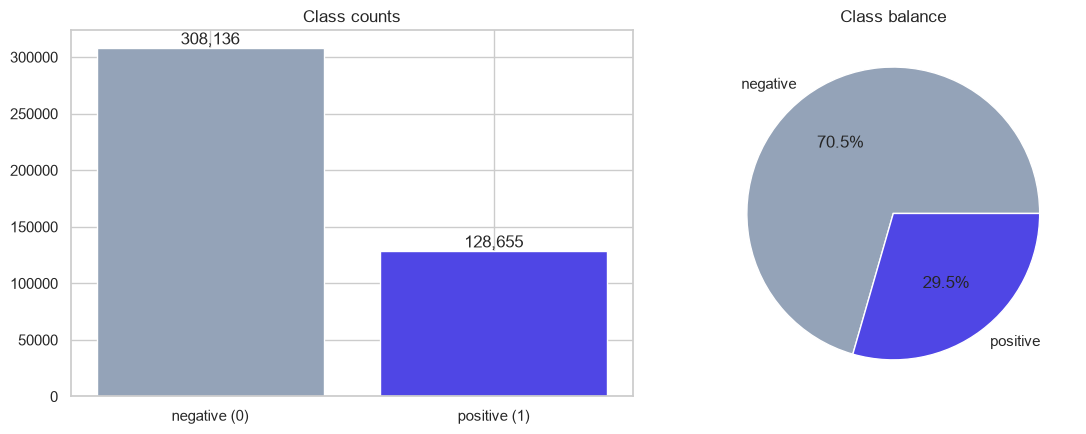

In [5]:
# Step 5: target distribution and balance
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
vc = df_labeled['target'].value_counts().sort_index()
ax[0].bar(['negative (0)', 'positive (1)'], vc.values, color=['#94a3b8', '#4f46e5'])
for i, v in enumerate(vc.values): ax[0].text(i, v, f'{v:,}', ha='center', va='bottom')
ax[0].set_title('Class counts')
ax[1].pie(vc.values, labels=['negative', 'positive'], autopct='%1.1f%%', colors=['#94a3b8', '#4f46e5'])
ax[1].set_title('Class balance')
plt.tight_layout(); plt.savefig(FIG / 'target_distribution.png', dpi=150); plt.show()

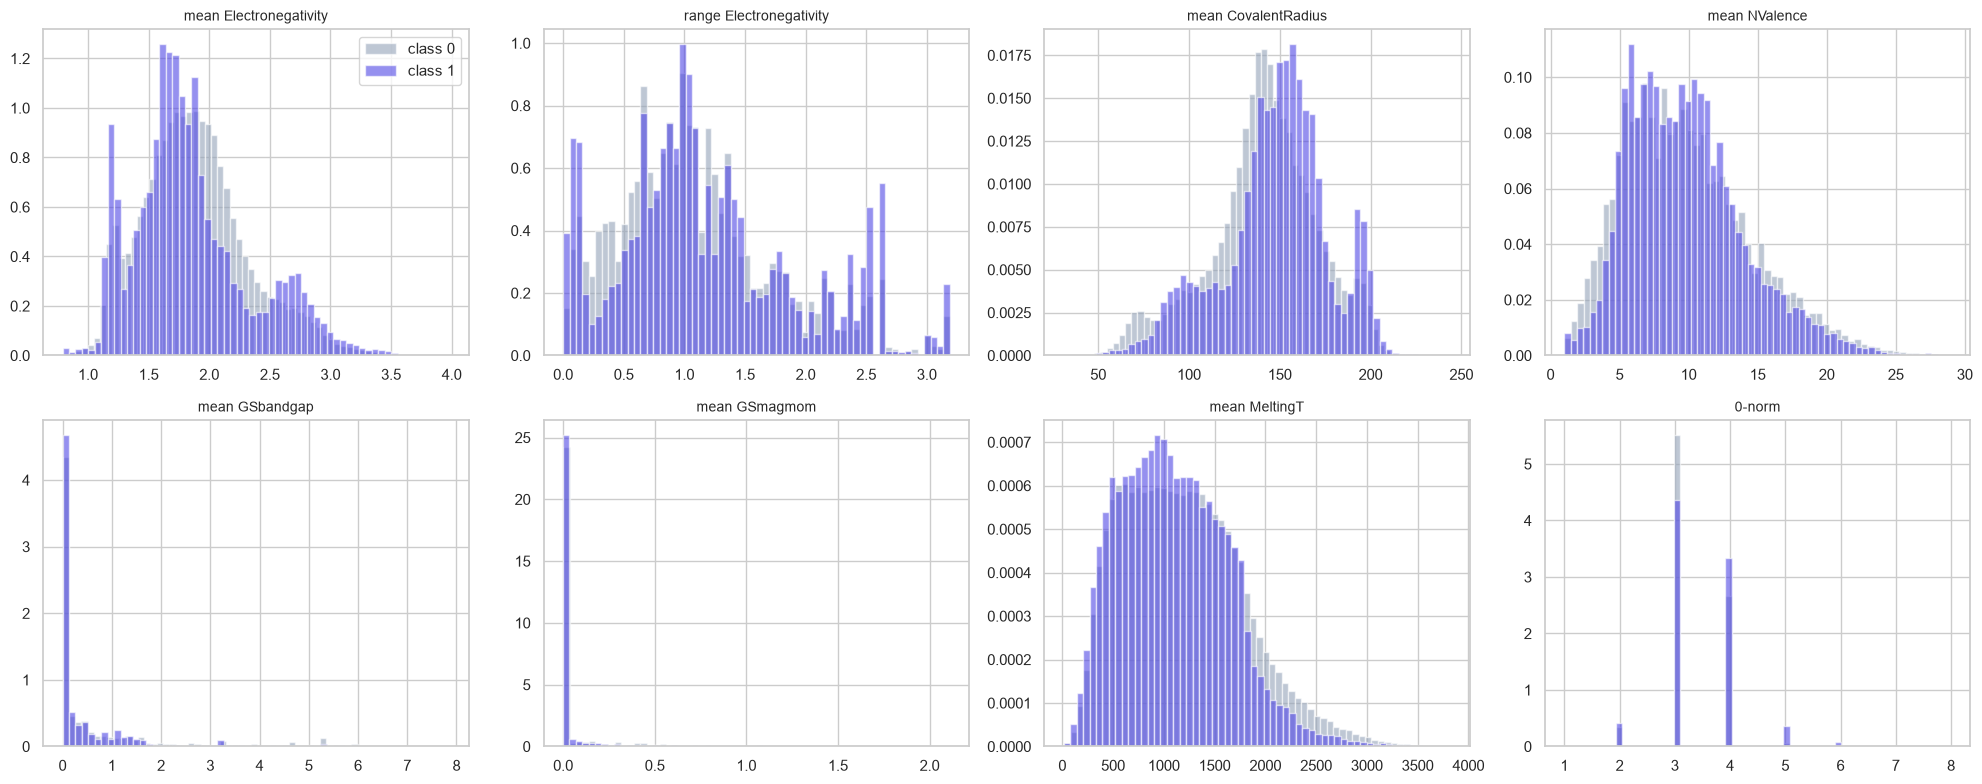

In [6]:
# Step 6: key descriptors by class
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.flat, key):
    for y, col in ((0, '#94a3b8'), (1, '#4f46e5')):
        ax.hist(df_labeled.loc[df_labeled.target == y, c].dropna(), bins=60, alpha=.6, density=True, color=col, label=f'class {y}')
    ax.set_title(c.replace('MagpieData ', ''), fontsize=10)
axes[0, 0].legend()
plt.tight_layout(); plt.savefig(FIG / 'descriptors_by_class.png', dpi=150); plt.show()

CORRELATION ANALYSIS (Threshold: 0.5)


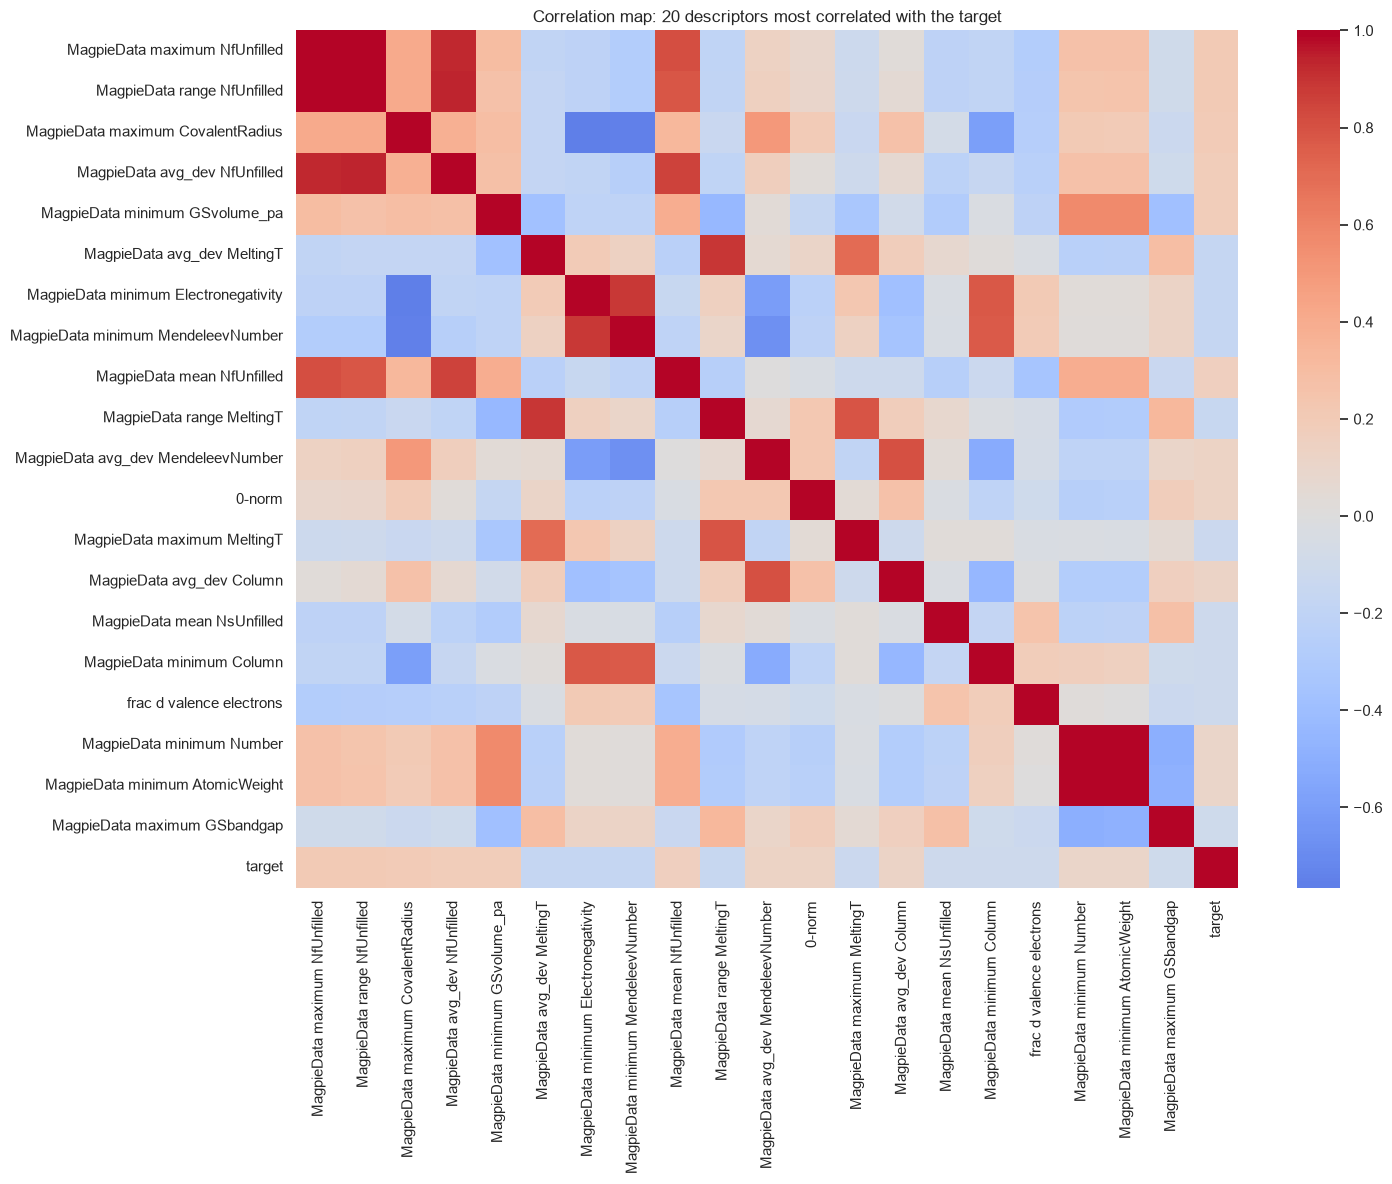

descriptor pairs with |r| > 0.5: 750 of 10,011
top correlations with target:


MagpieData maximum NfUnfilled           0.212436
MagpieData range NfUnfilled             0.209066
MagpieData maximum CovalentRadius       0.194840
MagpieData avg_dev NfUnfilled           0.186197
MagpieData minimum GSvolume_pa          0.184579
MagpieData avg_dev MeltingT             0.171398
MagpieData minimum Electronegativity    0.168326
MagpieData minimum MendeleevNumber      0.167403
MagpieData mean NfUnfilled              0.159109
MagpieData range MeltingT               0.153204
dtype: float64

In [7]:
# Step 7: Pearson correlation matrix (threshold 0.5)
print("=" * 80); print("CORRELATION ANALYSIS (Threshold: 0.5)"); print("=" * 80)
corr_t = df_labeled[feat].corrwith(df_labeled['target']).abs().sort_values(ascending=False)
top = corr_t.head(20).index.tolist()
C = df_labeled[top + ['target']].corr()
plt.figure(figsize=(15, 12)); sns.heatmap(C, cmap='coolwarm', center=0, annot=False)
plt.title('Correlation map: 20 descriptors most correlated with the target')
plt.tight_layout(); plt.savefig(FIG / 'correlation_map.png', dpi=150); plt.show()
full = df_labeled[feat].corr().abs()
pairs = (full.where(np.triu(np.ones(full.shape), 1).astype(bool)).stack())
print(f"descriptor pairs with |r| > 0.5: {(pairs > 0.5).sum():,} of {len(pairs):,}")
print("top correlations with target:"); corr_t.head(10)

## Unlabeled Data

In [8]:
# Load the unlabeled pool (GNoME), excluding compositions present in the labeled set
df_unlabeled = pd.read_parquet(ROOT / "data/processed/unlabeled_gnome_features.parquet")
df_unlabeled = df_unlabeled[~df_unlabeled.formula.isin(set(df_labeled.formula))]
print(f"Labeled data:   {len(df_labeled):,} compositions")
print(f"Unlabeled data: {len(df_unlabeled):,} compositions (GNoME)")
print(f"Ratio unlabeled/labeled: {len(df_unlabeled) / len(df_labeled):.1f}")

Labeled data:   436,791 compositions
Unlabeled data: 548,412 compositions (GNoME)
Ratio unlabeled/labeled: 1.3


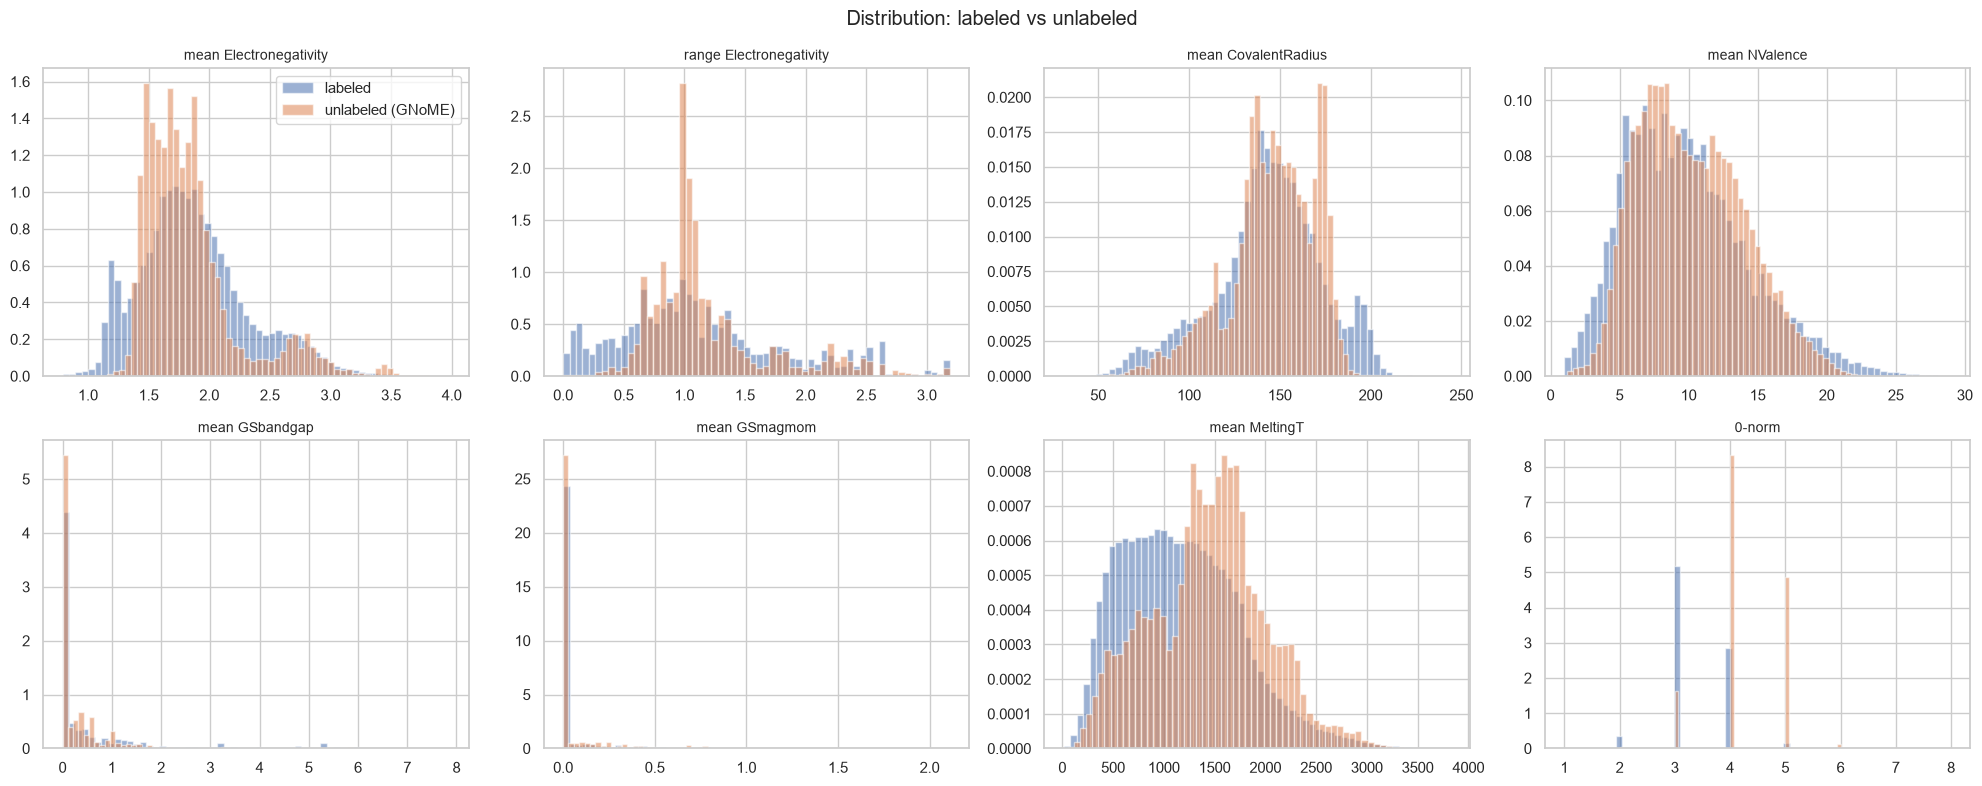

In [9]:
# Compare feature distributions between labeled and unlabeled data
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
sample_u = df_unlabeled.sample(min(100000, len(df_unlabeled)), random_state=0)
for ax, c in zip(axes.flat, key):
    ax.hist(df_labeled[c].dropna(), bins=60, alpha=.55, density=True, label='labeled')
    ax.hist(sample_u[c].dropna(), bins=60, alpha=.55, density=True, label='unlabeled (GNoME)')
    ax.set_title(c.replace('MagpieData ', ''), fontsize=10)
axes[0, 0].legend()
plt.suptitle('Distribution: labeled vs unlabeled')
plt.tight_layout(); plt.savefig(FIG / 'labeled_vs_unlabeled.png', dpi=150); plt.show()

In [10]:
# Statistical tests: are the distributions similar? (Kolmogorov-Smirnov)
from scipy.stats import ks_2samp
rows = []
for c in key:
    s, p = ks_2samp(df_labeled[c].dropna(), sample_u[c].dropna())
    rows.append({'feature': c, 'KS statistic': s, 'p-value': p, 'similar (KS<0.1)': s < 0.1})
pd.DataFrame(rows)

,feature,KS statistic,p-value,similar (KS<0.1)
0,MagpieData mean Electronegativity,0.128594,0.0,False
1,MagpieData range Electronegativity,0.193779,0.0,False
2,MagpieData mean CovalentRadius,0.077700,0.0,True
3,MagpieData mean NValence,0.081193,0.0,True
4,MagpieData mean GSbandgap,0.109039,0.0,False
5,MagpieData mean GSmagmom,0.125678,0.0,False
6,MagpieData mean MeltingT,0.245989,0.0,False
7,0-norm,0.535011,0.0,False


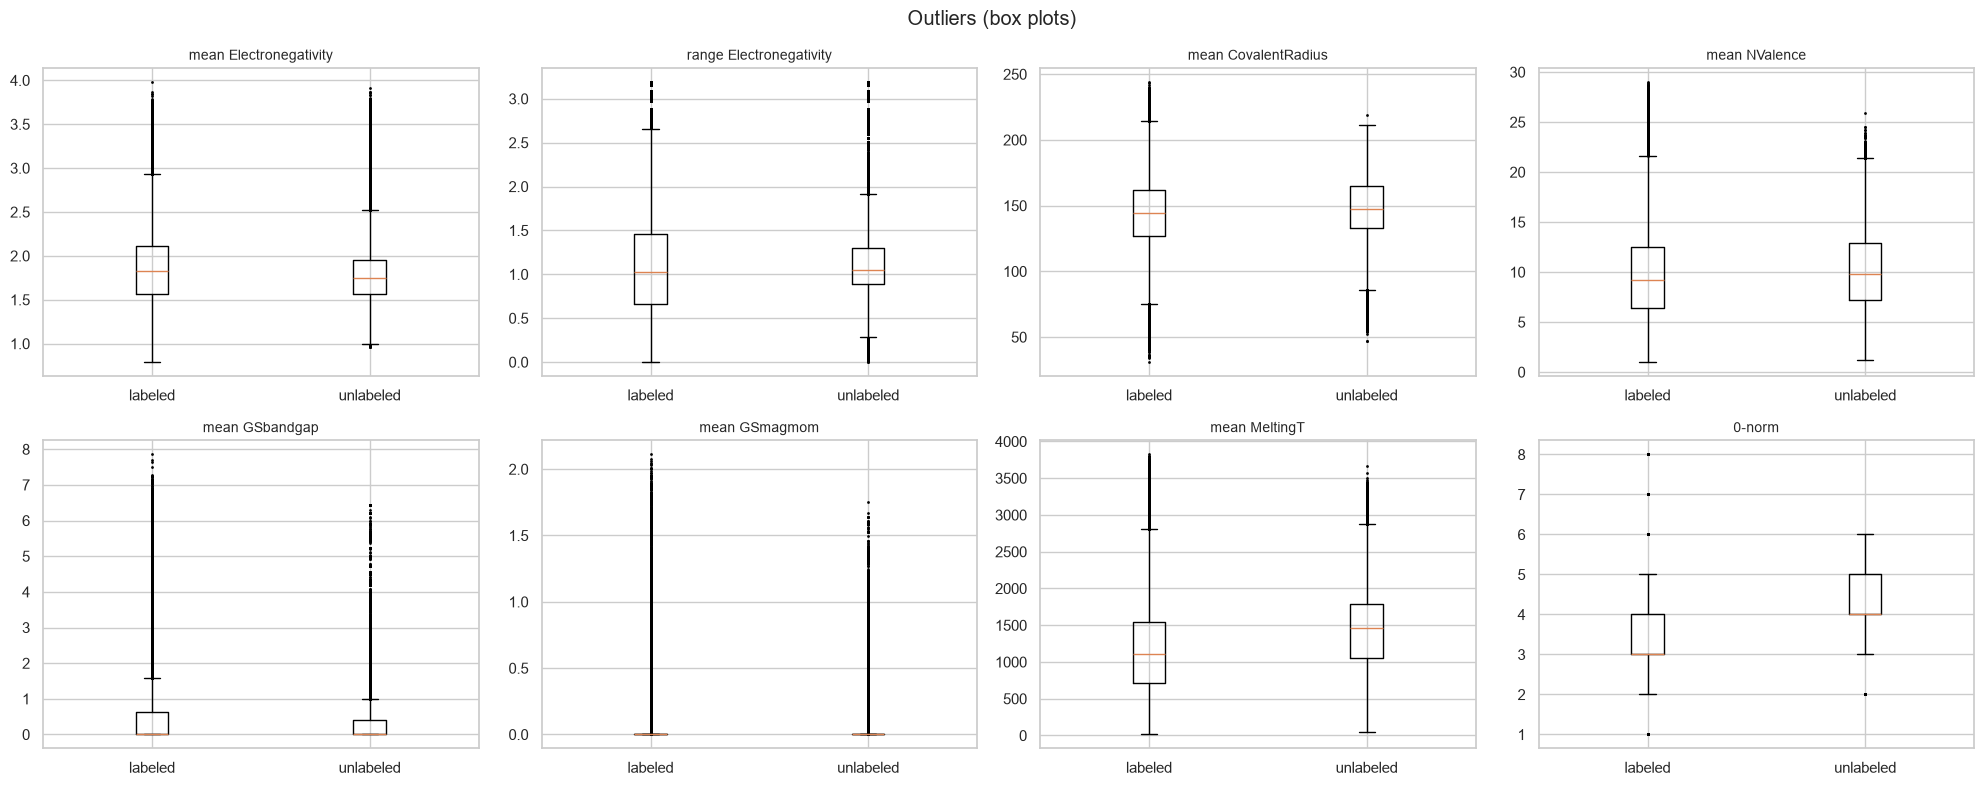

values beyond 3 std: 484,625 (0.78% of all values)


In [11]:
# Box plots for outlier comparison
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.flat, key):
    ax.boxplot([df_labeled[c].dropna(), sample_u[c].dropna()], tick_labels=['labeled', 'unlabeled'], showfliers=True, flierprops={'markersize': 1})
    ax.set_title(c.replace('MagpieData ', ''), fontsize=10)
plt.suptitle('Outliers (box plots)'); plt.tight_layout(); plt.savefig(FIG / 'outliers.png', dpi=150); plt.show()
z = (df_labeled[feat] - df_labeled[feat].mean()) / df_labeled[feat].std()
print(f"values beyond 3 std: {(z.abs() > 3).sum().sum():,} ({(z.abs() > 3).mean().mean():.2%} of all values)")

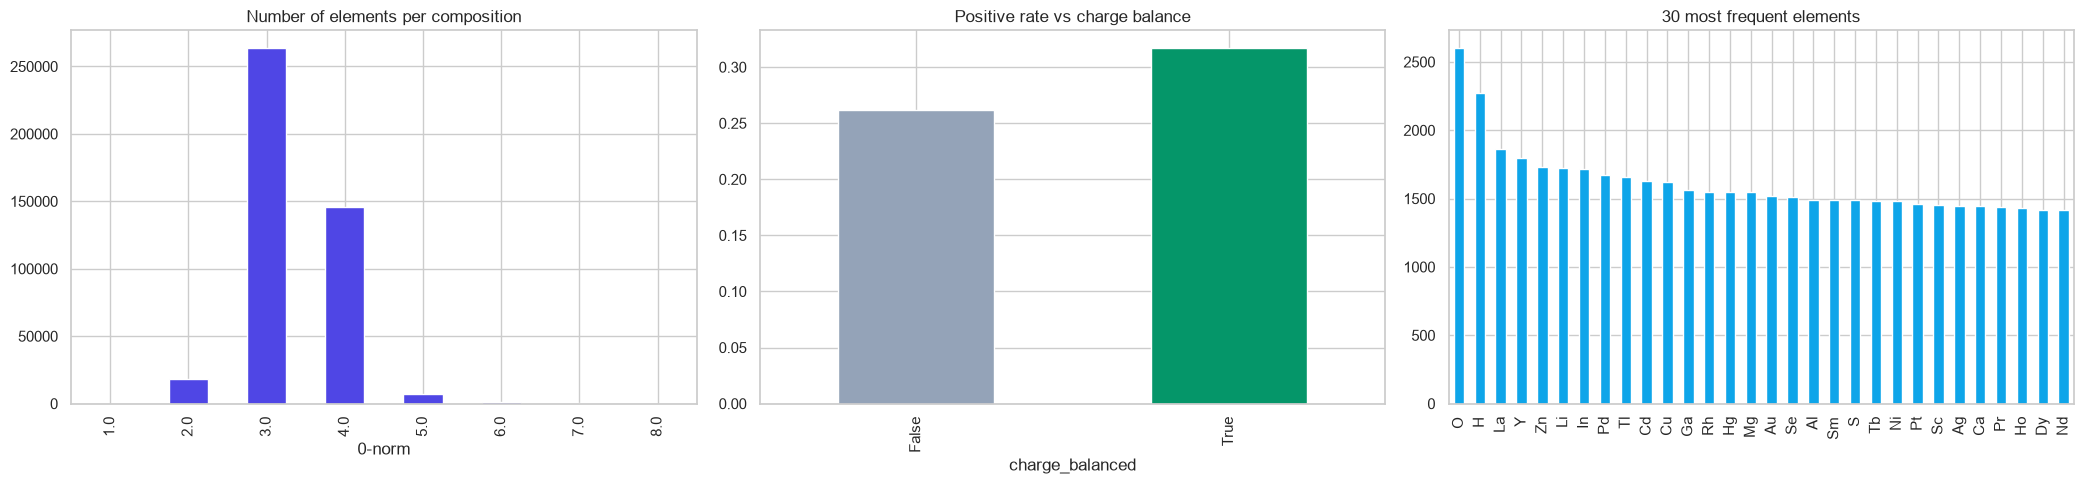

charge-balanced fraction: 25.6%


In [12]:
# Chemical rules: number of elements, charge balance, element frequency
from pymatgen.core import Composition
smp = df_labeled.sample(3000, random_state=0)
def balanced(f):
    try:
        return len(Composition(f).oxi_state_guesses(max_sites=-50)) > 0
    except Exception:
        return False
smp = smp.assign(charge_balanced=smp.formula.map(balanced))
els = pd.Series([e.symbol for f in df_labeled.formula.sample(30000, random_state=0) for e in Composition(f).elements]).value_counts()
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
df_labeled['0-norm'].value_counts().sort_index().plot.bar(ax=axes[0], color='#4f46e5'); axes[0].set_title('Number of elements per composition')
smp.groupby('charge_balanced')['target'].mean().plot.bar(ax=axes[1], color=['#94a3b8', '#059669']); axes[1].set_title('Positive rate vs charge balance')
els.head(30).plot.bar(ax=axes[2], color='#0ea5e9'); axes[2].set_title('30 most frequent elements')
plt.tight_layout(); plt.savefig(FIG / 'chemical_rules.png', dpi=150); plt.show()
print(f"charge-balanced fraction: {smp.charge_balanced.mean():.1%}")

## Data Processing

In [13]:
# Step 1: keep all informative features (drop constant ones)
print("=" * 80)
print("STEP 1: FEATURE SELECTION - KEEPING ALL FEATURES")
print("=" * 80)
keep = [c for c in feat if df_labeled[c].nunique() > 1]
print(f"{len(keep)} informative descriptors kept, {len(feat) - len(keep)} constant removed")

STEP 1: FEATURE SELECTION - KEEPING ALL FEATURES


142 informative descriptors kept, 0 constant removed


In [14]:
# Step 2: handle outliers (clipping at mean +- 3 std) and impute missing values
print("STEP 2: HANDLE OUTLIERS (CLIPPING)")
X_raw = df_labeled[keep].fillna(df_labeled[keep].median())
lo, hi = X_raw.mean() - 3 * X_raw.std(), X_raw.mean() + 3 * X_raw.std()
n_clip = ((X_raw < lo) | (X_raw > hi)).sum().sum()
X_clip = X_raw.clip(lo, hi, axis=1)
print(f"clipped values: {n_clip:,} ({n_clip / X_raw.size:.2%})")

STEP 2: HANDLE OUTLIERS (CLIPPING)


clipped values: 484,625 (0.78%)


STEP 3: Z-SCORE NORMALIZATION


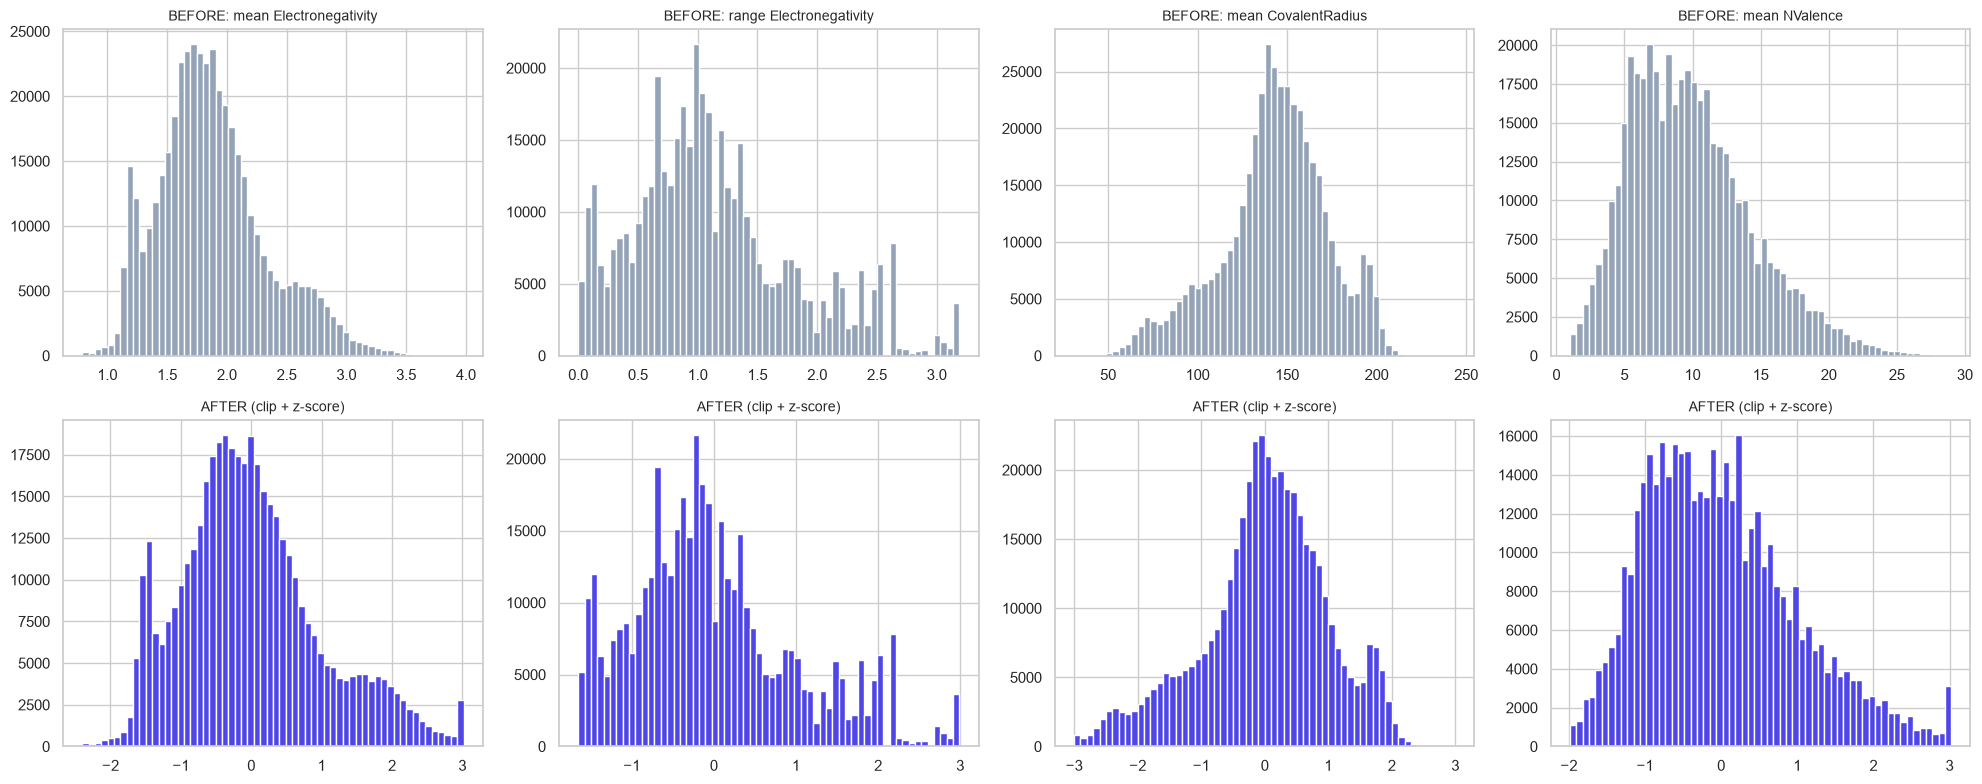

,mean before,std before,mean after,std after
MagpieData mean Electronegativity,1.875,0.454,-0.0,1.0
MagpieData range Electronegativity,1.135,0.687,0.0,1.0
MagpieData mean CovalentRadius,142.856,29.843,0.0,1.0
MagpieData mean NValence,9.817,4.469,-0.0,1.0


In [15]:
# Step 3: z-score normalisation (StandardScaler) – before vs after
print("STEP 3: Z-SCORE NORMALIZATION")
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_clip)
X_scaled = pd.DataFrame(scaler.transform(X_clip), columns=keep)
show = key[:4]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for j, c in enumerate(show):
    axes[0, j].hist(X_raw[c], bins=60, color='#94a3b8'); axes[0, j].set_title('BEFORE: ' + c.replace('MagpieData ', ''), fontsize=10)
    axes[1, j].hist(X_scaled[c], bins=60, color='#4f46e5'); axes[1, j].set_title('AFTER (clip + z-score)', fontsize=10)
plt.tight_layout(); plt.savefig(FIG / 'normalization_before_after.png', dpi=150); plt.show()
pd.DataFrame({'mean before': X_raw[show].mean(), 'std before': X_raw[show].std(), 'mean after': X_scaled[show].mean(), 'std after': X_scaled[show].std()}).round(3)

In [16]:
# Step 4-5: combine with target, final dataset statistics
print("=" * 80); print("FINAL OUTPUT OF THE PREPROCESSING PIPELINE"); print("=" * 80)
print(f"Labeled compositions  : {len(df_labeled):,}")
print(f"Unlabeled compositions: {len(df_unlabeled):,}")
print(f"Descriptors           : {len(keep)}")
print(f"Positive rate         : {df_labeled['target'].mean():.3f}")
print("The scaler is fitted on training data only inside the training pipeline (pipeline/run_ssl_experiments.py) and saved to app/models/ for inference.")

FINAL OUTPUT OF THE PREPROCESSING PIPELINE
Labeled compositions  : 436,791
Unlabeled compositions: 548,412
Descriptors           : 142
Positive rate         : 0.295
The scaler is fitted on training data only inside the training pipeline (pipeline/run_ssl_experiments.py) and saved to app/models/ for inference.
